In [ ]:
# ==============================================================================
# CELL 1: Imports & Data Ingestion
# ==============================================================================
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to system path so we can import from 'src'
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_prep import load_and_standardize_data
from src.config import TARGET_COL


# Set visual styling for clean, portfolio-ready charts
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

# Load standardized snake_case data
df = load_and_standardize_data()
print(f"Dataset Shape: {df.shape}")
df.head(3)


2026-11-23 16:07:34,542 - INFO - Loading raw dataset from: C:\Users\navee\Downloads\telco-churn-prediction\data\raw\Telco_customer_churn.xlsx
2026-11-23 16:07:35,815 - INFO - Raw data loaded successfully. Shape: (7043, 33)
2026-11-23 16:07:35,817 - INFO - Column names standardized to snake_case.


Dataset Shape: (7043, 33)


,customerid,count,country,state,city,zip_code,lat_long,latitude,longitude,gender,...,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn_label,churn_value,churn_score,cltv,churn_reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved


In [2]:
# ==============================================================================
# CELL 2: Structural Audit (Data Types, Missing Values & Duplicates)
# ==============================================================================
def audit_dataframe(data: pd.DataFrame) -> pd.DataFrame:
    """Generates a comprehensive summary of data types, nulls, and unique counts."""
    summary = pd.DataFrame({
        "dtype": data.dtypes,
        "missing_count": data.isnull().sum(),
        "missing_pct": (data.isnull().sum() / len(data) * 100).round(2),
        "unique_values": data.nunique(),
        "sample_value": data.iloc[0]
    })
    return summary

print(f"Exact Duplicate Rows: {df.duplicated().sum()}")
if "customerid" in df.columns:
    print(f"Duplicate Customer IDs: {df['customerid'].duplicated().sum()}")

audit_table = audit_dataframe(df)
display(audit_table)


Exact Duplicate Rows: 0
Duplicate Customer IDs: 0


,dtype,missing_count,missing_pct,unique_values,sample_value
customerid,str,0,0.00,7043,3668-QPYBK
count,int64,0,0.00,1,1
country,str,0,0.00,1,United States
state,str,0,0.00,1,California
city,str,0,0.00,1129,Los Angeles
zip_code,int64,0,0.00,1652,90003
lat_long,str,0,0.00,1652,"33.964131, -118.272783"
latitude,float64,0,0.00,1652,33.964131
longitude,float64,0,0.00,1651,-118.272783
gender,str,0,0.00,2,Male


In [3]:
# ==============================================================================
# CELL 3: Trap Detection (Hidden Strings in Numeric Columns & Leakage Columns)
# ==============================================================================
# 1. Check why 'total_charges' is often parsed as 'object' (string)
# Coerce to numeric to find rows with blank spaces (" ")
non_numeric_charges = df[pd.to_numeric(df["total_charges"], errors="coerce").isnull()]
print(f"Rows where 'total_charges' cannot be converted to float: {len(non_numeric_charges)}")
display(non_numeric_charges[["customerid", "tenure_months", "monthly_charges", "total_charges", TARGET_COL]])

# 2. Check Target Distribution (Class Imbalance)
churn_counts = df[TARGET_COL].value_counts(normalize=True) * 100
print("\nTarget Class Distribution (%):")
print(churn_counts.round(2))

# 3. Inspect Leakage Columns (Specific to IBM Telco XLSX dataset)
leakage_candidates = ["churn_label", "churn_score", "churn_reason", "count"]
existing_leakage = [col for col in leakage_candidates if col in df.columns]
print(f"\n⚠️ Potential Leakage / Redundant Columns Found: {existing_leakage}")
if "churn_reason" in df.columns:
    print("\nMissing values in 'churn_reason' grouped by actual churn:")
    print(df.groupby(TARGET_COL)["churn_reason"].apply(lambda x: x.isnull().sum()))


Rows where 'total_charges' cannot be converted to float: 11


,customerid,tenure_months,monthly_charges,total_charges,churn_value
2234,4472-LVYGI,0,52.55,,0
2438,3115-CZMZD,0,20.25,,0
2568,5709-LVOEQ,0,80.85,,0
2667,4367-NUYAO,0,25.75,,0
2856,1371-DWPAZ,0,56.05,,0
4331,7644-OMVMY,0,19.85,,0
4687,3213-VVOLG,0,25.35,,0
5104,2520-SGTTA,0,20.00,,0
5719,2923-ARZLG,0,19.70,,0
6772,4075-WKNIU,0,73.35,,0



Target Class Distribution (%):
churn_value
0    73.46
1    26.54
Name: proportion, dtype: float64

⚠️ Potential Leakage / Redundant Columns Found: ['churn_label', 'churn_score', 'churn_reason', 'count']

Missing values in 'churn_reason' grouped by actual churn:
churn_value
0    5174
1       0
Name: churn_reason, dtype: int64


2026-11-23 16:19:59,471 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-23 16:19:59,480 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


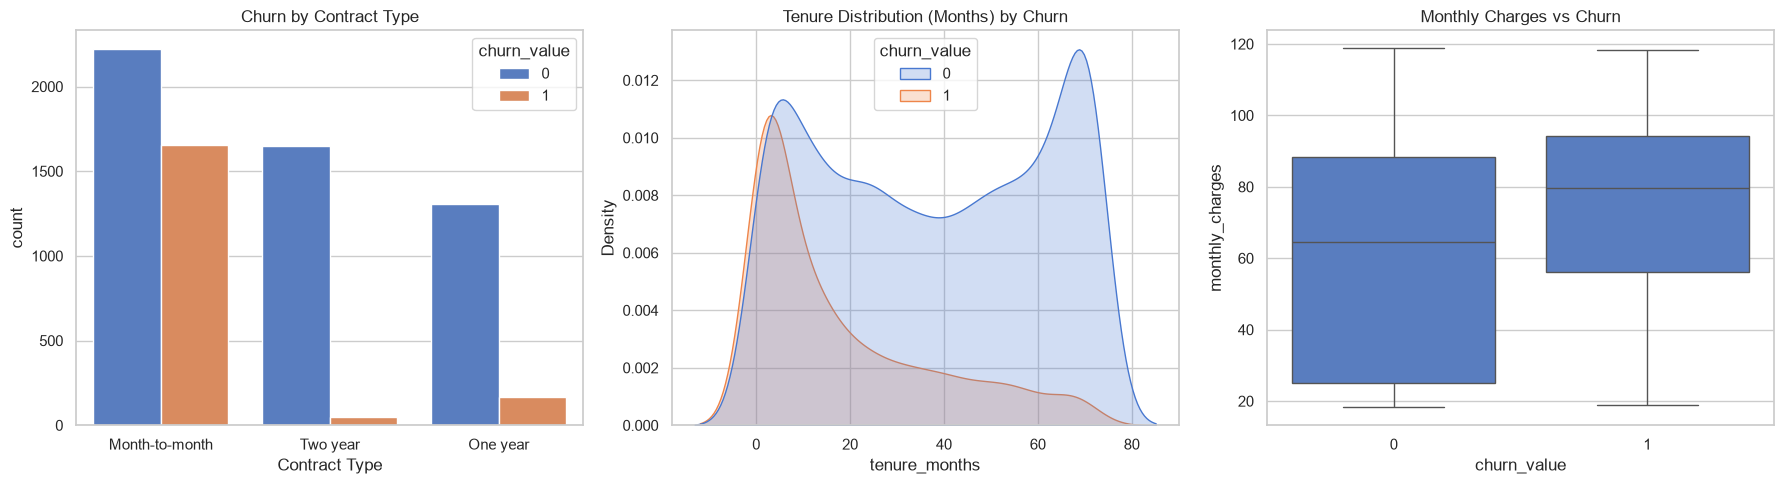

In [4]:
# ==============================================================================
# CELL 4: Business Hypothesis Visuals (Drivers of Churn)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Contract Type vs Churn
sns.countplot(data=df, x="contract", hue=TARGET_COL, ax=axes[0])
axes[0].set_title("Churn by Contract Type")
axes[0].set_xlabel("Contract Type")

# Plot 2: Tenure Months Distribution by Churn
sns.kdeplot(data=df, x="tenure_months", hue=TARGET_COL, fill=True, ax=axes[1])
axes[1].set_title("Tenure Distribution (Months) by Churn")

# Plot 3: Monthly Charges Distribution by Churn
sns.boxplot(data=df, x=TARGET_COL, y="monthly_charges", ax=axes[2])
axes[2].set_title("Monthly Charges vs Churn")

plt.tight_layout()
plt.show()


###  **Churn Driver Visuals se Mile Key Business Insights**

1. **Contract Type Sabse Bada Churn Predictor Hai (Left Plot):**
   * **Observation (Kya dikha):** **Month-to-month** contract wale customers sabse zyada churn karte hain (~1,650 churners vs ~2,220 retained, yaani **~42.7% churn rate**). Iske mukable **One-year** (~11%) aur **Two-year** (<3%) contracts mein churn na ke barabar hai.
   * **Why & Action:** Month-to-month customers par company chhodne ki koi rok-tok (switching barrier) nahi hoti. *Feature Engineering Action:* Humne ek explicit binary risk flag (`is_month_to_month`) banaya.

2. **Shuru ke Months mein Zyada Khatra aur Long-Term Loyalty (Middle Plot):**
   * **Observation (Kya dikha):** Churn density curve (`churn_value = 1`, orange) **0 se 12 months** ke beech tezi se upar jaata hai aur uske baad neeche girne lagta hai. Wahin rukne wale customers (`churn_value = 0`, blue) mein **65–72 months** ke aas-paas ek bada loyalty peak dikhta hai.
   * **Why & Action:** Jo customers apna pehla saal (first year) nikal lete hain, wo company ke saath lambe samay tak jude rehte hain. *Feature Engineering Action:* Humne `tenure_months` ko lifecycle stages (`tenure_group`: `0_12m`, `13_24m`, `25_48m`, `49m_plus`) mein bucket kiya.

3. **Price Sensitivity aur "Bill Shock" Effect (Right Plot):**
   * **Observation (Kya dikha):** Churn karne wale customers (`1`) ka median monthly bill kaafi zyada (**~$79.65**) hai (zyadatar **$56 se $94** ke beech), jabki rukne wale customers (`0`) ka median bill kam (**~$64.40**) hai aur **$25/month** ke basic plans tak neeche jaata hai.
   * **Why & Action:** Mehenge plans (jaise bina security/support bundle ke Fiber Optic) ki wajah se price ko lekar dissatisfaction badhta hai.
   * *Feature Engineering Action:* Achanak badhe hue bill ("bill shock") ko pakadne ke liye `avg_monthly_spend` aur `charge_diff_from_avg` features engineer kiye.


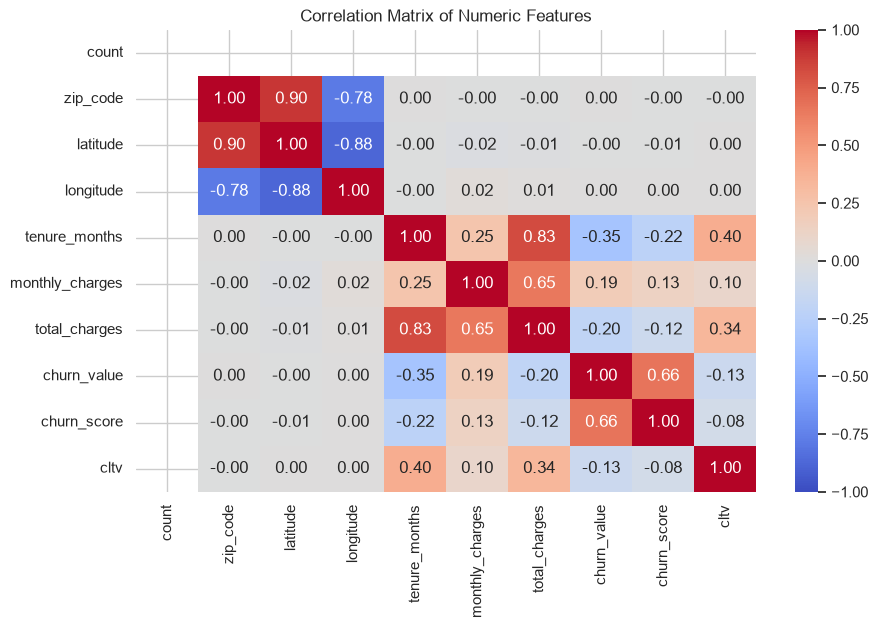

In [5]:
# ==============================================================================
# CELL 5: Geographic / High-Cardinality & Multicollinearity Check
# ==============================================================================
# Check numeric correlations
numeric_df = df.copy()
numeric_df["total_charges"] = pd.to_numeric(numeric_df["total_charges"], errors="coerce")

plt.figure(figsize=(10, 6))
corr = numeric_df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numeric Features")
plt.show()


###  **Correlation Matrix Heatmap se Mile Key Insights**

1. **Zero-Variance Column (`count` Row & Column Poora Blank Hai):**
   * **Kya dikha:** `count` column ki poori row aur column blank (white) hai kyunki isme har jagah sirf `1` likha hai (standard deviation = `0`).
   * **Action:** Isse confirm hota hai ki `count` mein zero information hai aur ise drop karna bilkul sahi hai.

2. **Data Leakage ka Pakka Saboot (`churn_score` vs `churn_value` = `0.66`):**
   * **Kya dikha:** `churn_score` ka target variable `churn_value` ke saath sabse high positive correlation (`0.66`) hai, kyunki ye IBM ke post-churn system se generate hua score hai.
   * **Action:** Real-world deployment mein naye customer ke paas ye score nahi hoga—isliye ise drop karna mandatory hai taaki data leakage na ho.

3. **Strong Multicollinearity (`tenure_months` vs `total_charges` = `0.83`):**
   * **Kya dikha:** `total_charges` ka `tenure_months` (`0.83`) aur `monthly_charges` (`0.65`) ke saath high correlation hai, kyunki `total_charges ≈ tenure_months × monthly_charges`.
   * **Action:** Is relationship ka fayda utha kar humne `avg_monthly_spend = total_charges / (tenure_months + 1)` aur `charge_diff_from_avg` engineer kiye, jo linear collinearity ko useful "bill shock" signal mein badalte hain.

4. **Geographic Redundancy (`zip_code` vs `latitude` = `0.90` & `longitude` = `-0.78`):**
   * **Kya dikha:** California mein `zip_code` aur `latitude`/`longitude` aapas mein tightly correlated hain (`0.90` aur `-0.88`).
   * **Action:** Numeric `latitude` aur `longitude` pehle hi poori spatial location capture kar lete hain, isliye raw `zip_code` ko drop karna redundant noise kam karta hai.

5. **Target Correlation (`churn_value` ke Main Numeric Drivers):**
   * `tenure_months` (`-0.35`): Jitna zyada tenure, utna kam churn (strongest negative correlation).
   * `monthly_charges` (`+0.19`): Zyada monthly bill churn risk badhata hai.
   * `cltv` (`-0.13`): High Customer Lifetime Value wale loyal customers kam churn karte hain.
